In [8]:
import pandas as pd
import glob
import os
import numpy as np
import ast
from scipy.stats import pearsonr
import joblib
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error, r2_score
from collections import Counter

# Setting plot style
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['Inter', 'Roboto', 'Arial']

OUTPUT_DIR = "../results_comparison_all_models"
if not os.path.exists(OUTPUT_DIR):
    os.makedirs(OUTPUT_DIR)


In [9]:
VAL_DATA_DIR = "../val_data"

# Model Result Directories
MODEL_DIRS = {
    'Model_Z':    "../results_val",
    'Model_Rank': "../results_rk",
    'Model_Bin':  "../results_bin",
    'Model_None': "../results_none"
}


In [10]:
model_dfs = {}
all_proteins = []

for m_name, m_dir in MODEL_DIRS.items():
    print(f"Loading {m_name} from {m_dir}...")
    best_files = glob.glob(os.path.join(m_dir, "*_best.csv"))
    
    dfs = []
    for f in best_files:
        try:
            df = pd.read_csv(f)
            dfs.append(df)
        except Exception: pass
        
    if dfs:
        full_df = pd.concat(dfs, ignore_index=True)
        # Create dictionary for quick lookup: protein -> coeff_dict
        model_dfs[m_name] = full_df.set_index('protein')['feat_coeffs_dict'].to_dict()
        print(f"  Loaded {len(model_dfs[m_name])} models.")
        all_proteins.append(set(model_dfs[m_name].keys()))
    else:
        print(f"  No models found for {m_name}")
        model_dfs[m_name] = {}
        all_proteins.append(set())

# Find Intersection
if all_proteins:
    common_proteins = set.intersection(*all_proteins)
    common_proteins = sorted(list(common_proteins))
    print(f"\nIntersection: {len(common_proteins)} proteins common to all 4 models.")
else:
    common_proteins = []
    print("No models loaded.")


Loading Model_Z from ../results_val...
  Loaded 1809 models.
Loading Model_Rank from ../results_rk...
  Loaded 600 models.
Loading Model_Bin from ../results_bin...
  Loaded 2141 models.
Loading Model_None from ../results_none...
  Loaded 2128 models.

Intersection: 488 proteins common to all 4 models.


In [11]:
datasets = ['iTRAQ', 'LabelFree', 'TMT']
comparison_results = []

for ds in datasets:
    RNA_PATH = os.path.join(VAL_DATA_DIR, f"{ds}_transcriptomics.joblib")
    PROT_PATH = os.path.join(VAL_DATA_DIR, f"{ds}_proteomics.joblib")
    
    if not (os.path.exists(RNA_PATH) and os.path.exists(PROT_PATH)):
        continue
        
    print(f"\nEvaluating on {ds} dataset...")
    rna_df = joblib.load(RNA_PATH).fillna(0)
    prot_df = joblib.load(PROT_PATH)
    
    available_feats = set(rna_df.columns)
    
    # Store results for this dataset
    ds_res = {'Dataset': ds}
    
    # Evaluate each model type ON THE COMMON PROTEINS ONLY
    for m_name in MODEL_DIRS.keys():
        y_preds = []
        y_trues = []
        
        warned = False
        
        for p in common_proteins:
            if p not in prot_df.columns: 
                continue 
            
            # Get model coefficients
            coef_str = model_dfs[m_name][p]
            coeffs = ast.literal_eval(coef_str)
            needed = list(coeffs.keys())
            
            # FIX: Check for missing features and impute 0
            current_missing = [f for f in needed if f not in available_feats]
            
            if current_missing:
                if not warned:
                    print(f"  [{m_name}] Note: Missing features for {p} (and others). Imputing 0.")
                    warned = True
                
                present_feats = [f for f in needed if f in available_feats]
                if not present_feats:
                     yp = np.zeros(rna_df.shape[0])
                else:
                     weights_present = np.array([coeffs[f] for f in present_feats])
                     X_present = rna_df[present_feats]
                     yp = X_present.dot(weights_present)
            else:
                # Standard path
                weights = np.array([coeffs[f] for f in needed])
                X = rna_df[needed]
                yp = X.dot(weights)

            yt = prot_df[p]
            
            y_preds.append(yp.values)
            y_trues.append(yt.values)
            
        # Convert to matrix
        if not y_preds:
            print(f"  No valid predictions for {m_name} on {ds}")
            continue
            
        yp_mat = np.array(y_preds).T
        yt_mat = np.array(y_trues).T
        
        # Calculate Vectors of Metrics (Protein-wise)
        pcc_list, mse_list, cos_list = [], [], []
        
        for i in range(yp_mat.shape[1]): # Iterate proteins (columns)
            y_p_col = yp_mat[:, i]
            y_t_col = yt_mat[:, i]
            mask = (~np.isnan(y_p_col)) & (~np.isnan(y_t_col))
            
            if mask.sum() > 2:
                r, _ = pearsonr(y_t_col[mask], y_p_col[mask])
                mse = mean_squared_error(y_t_col[mask], y_p_col[mask])
                denom = (np.linalg.norm(y_p_col[mask]) * np.linalg.norm(y_t_col[mask]))
                cos = np.dot(y_p_col[mask], y_t_col[mask]) / denom if denom > 0 else 0.0
                
                pcc_list.append(r)
                mse_list.append(mse)
                cos_list.append(cos)
            else:
                pcc_list.append(np.nan)
                mse_list.append(np.nan)
                cos_list.append(np.nan)
                
        # Store aggregations
        ds_res[f'{m_name}_Mean_PCC'] = np.nanmean(pcc_list)
        ds_res[f'{m_name}_Mean_MSE'] = np.nanmean(mse_list)
        ds_res[f'{m_name}_Mean_Cosine'] = np.nanmean(cos_list)
        
        # Store raw lists for distribution plotting if needed
        ds_res[f'{m_name}_PCC_List'] = np.array(pcc_list)
        ds_res[f'{m_name}_MSE_List'] = np.array(mse_list)
        ds_res[f'{m_name}_Cosine_List'] = np.array(cos_list)
        
    comparison_results.append(ds_res)

# Create DataFrame
comp_df = pd.DataFrame(comparison_results)
print("\n=== Model Comparison on Intersection ===")
cols = [c for c in comp_df.columns if 'List' not in c]
display(comp_df[cols].round(4))



Evaluating on iTRAQ dataset...
  [Model_Z] Note: Missing features for A2M (and others). Imputing 0.
  [Model_Rank] Note: Missing features for A2M (and others). Imputing 0.
  [Model_Bin] Note: Missing features for A2M (and others). Imputing 0.
  [Model_None] Note: Missing features for A2M (and others). Imputing 0.

Evaluating on LabelFree dataset...
  [Model_Z] Note: Missing features for A2M (and others). Imputing 0.
  [Model_Rank] Note: Missing features for A2M (and others). Imputing 0.
  [Model_Bin] Note: Missing features for A2M (and others). Imputing 0.
  [Model_None] Note: Missing features for A2M (and others). Imputing 0.

Evaluating on TMT dataset...
  [Model_Z] Note: Missing features for A2M (and others). Imputing 0.
  [Model_Rank] Note: Missing features for A2M (and others). Imputing 0.
  [Model_Bin] Note: Missing features for A2M (and others). Imputing 0.
  [Model_None] Note: Missing features for A2M (and others). Imputing 0.

=== Model Comparison on Intersection ===


,Dataset,Model_Z_Mean_PCC,Model_Z_Mean_MSE,Model_Z_Mean_Cosine,Model_Rank_Mean_PCC,Model_Rank_Mean_MSE,Model_Rank_Mean_Cosine,Model_Bin_Mean_PCC,Model_Bin_Mean_MSE,Model_Bin_Mean_Cosine,Model_None_Mean_PCC,Model_None_Mean_MSE,Model_None_Mean_Cosine
0,iTRAQ,0.0188,1.2686,0.0114,0.0211,0.3410,0.0204,-0.0035,0.3452,-0.0005,0.0318,0.4585,0.0244
1,LabelFree,0.0907,3.0747,0.0926,0.0214,0.9806,0.0228,-0.0634,1.0070,-0.0652,0.0816,1.3895,0.0848
2,TMT,0.1311,12.9094,0.1298,-0.0066,10.4531,-0.0067,-0.1207,10.5286,-0.1185,0.0871,10.9204,0.0857


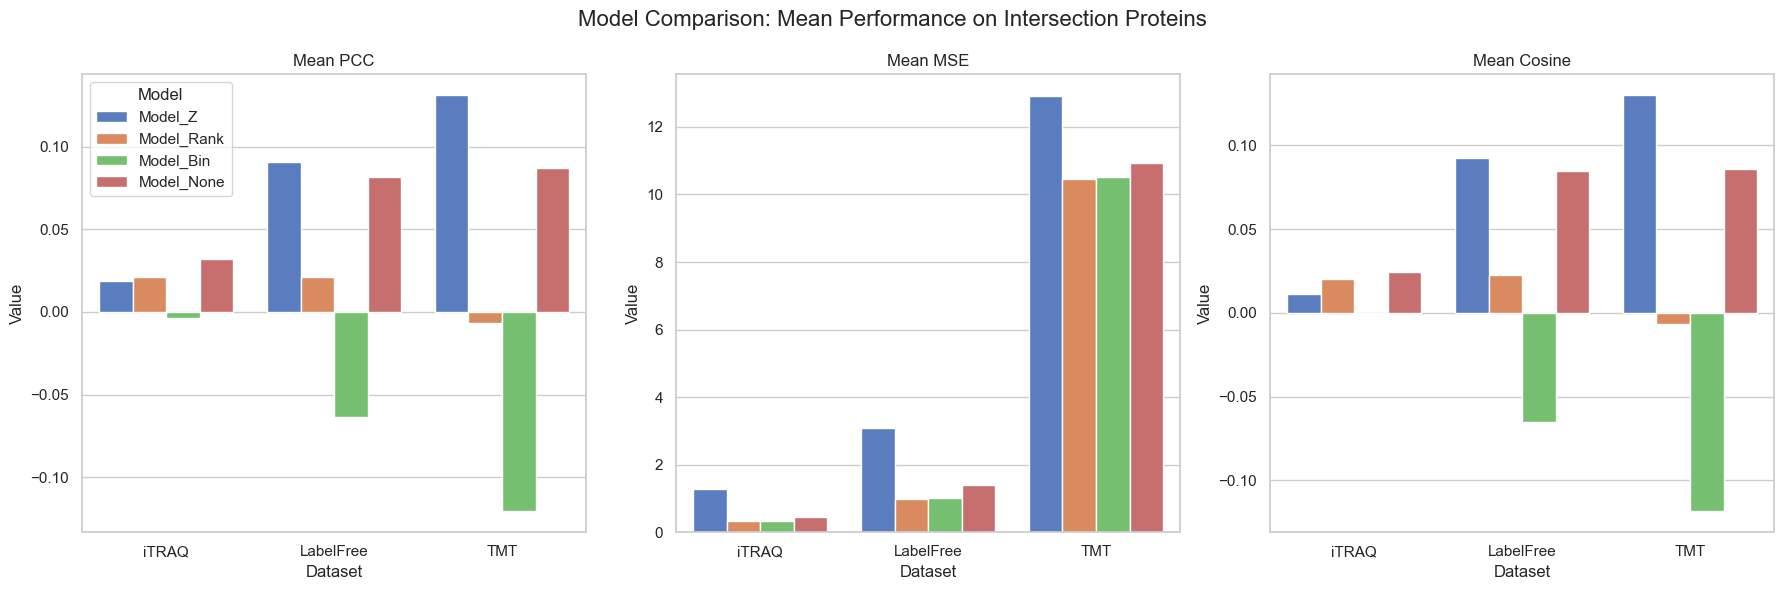

In [12]:
# 1. Bar Chart of Means
metrics = ['PCC', 'MSE', 'Cosine']
models = ['Model_Z', 'Model_Rank', 'Model_Bin', 'Model_None']

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
fig.suptitle('Model Comparison: Mean Performance on Intersection Proteins', fontsize=16)

palette = sns.color_palette("muted", len(models))

for i, metric in enumerate(metrics):
    ax = axes[i]
    # Prepare data for plotting
    plot_data = []
    for _, row in comp_df.iterrows():
        ds = row['Dataset']
        for m in models:
            val = row.get(f'{m}_Mean_{metric}', np.nan)
            plot_data.append({'Dataset': ds, 'Model': m, 'Value': val})
            
    df_plot = pd.DataFrame(plot_data)
    sns.barplot(data=df_plot, x='Dataset', y='Value', hue='Model', ax=ax, palette=palette)
    ax.set_title(f'Mean {metric}')
    if i > 0: ax.get_legend().remove()

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, 'model_comparison_bars.png'))
plt.show()    



=== Winning Model Analysis (Sample-wise Breakdown) ===

Dataset: iTRAQ


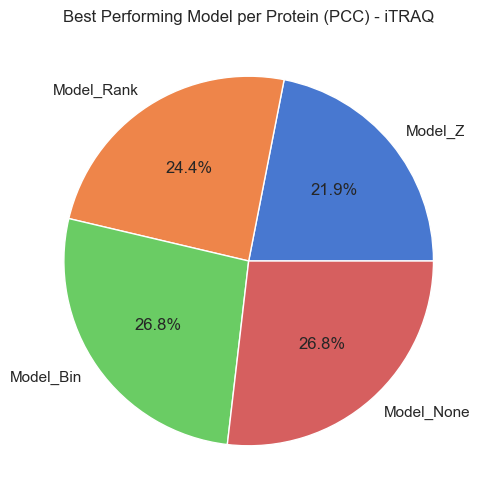


Dataset: LabelFree


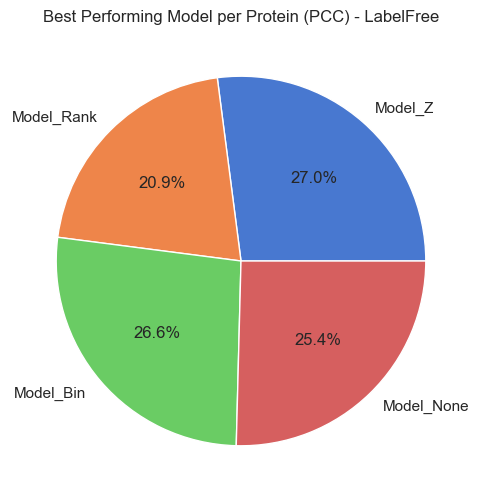


Dataset: TMT


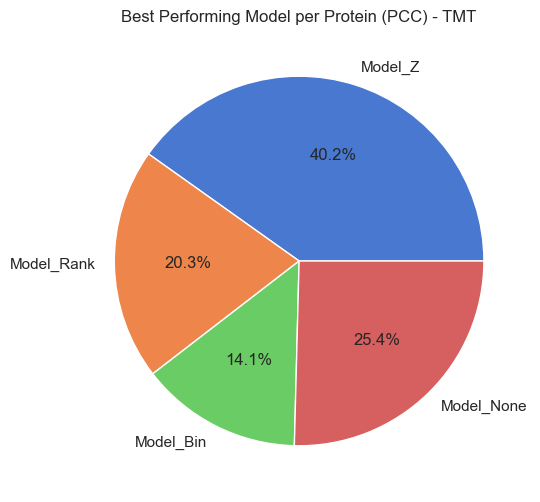

In [13]:
# 2. Winning Model Counts (PCC)
print("\n=== Winning Model Analysis (Sample-wise Breakdown) ===")

datasets_eval = comp_df['Dataset'].unique()
models_indices = {i: m for i, m in enumerate(models)} # 0: Z, 1: Rank, 2: Bin, 3: None

for ds in datasets_eval:
    print(f"\nDataset: {ds}")
    row = comp_df[comp_df['Dataset'] == ds].iloc[0]
    
    # Retrieve lists
    arrays = []
    for m in models:
        arrays.append(row.get(f'{m}_PCC_List', []))
        
    # Check emptiness
    if any(len(x) == 0 for x in arrays): continue
    
    # Stack
    stack = np.vstack(arrays) # Shape (4, n_proteins)
    
    # Find winner (Max PCC)
    winners_idx = np.argmax(stack, axis=0) 
    
    counts = Counter(winners_idx)
    
    # Pie Chart
    plt.figure(figsize=(6, 6))
    sizes = [counts.get(i, 0) for i in range(len(models))]
    plt.pie(sizes, labels=[models_indices[i] for i in range(len(models))], autopct='%1.1f%%', colors=palette)
    plt.title(f'Best Performing Model per Protein (PCC) - {ds}')
    plt.show()



=== Winning Model Analysis (MSE) ===

Dataset: iTRAQ


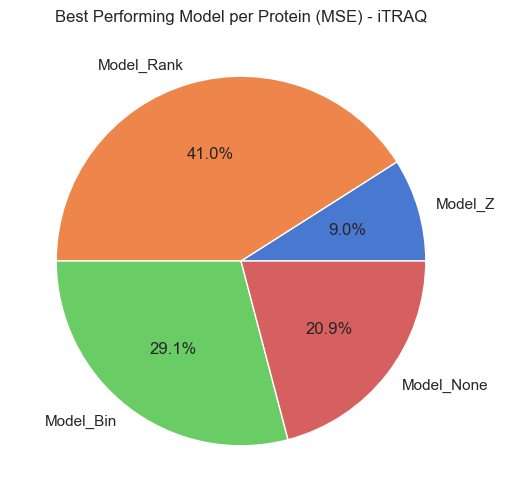


Dataset: LabelFree


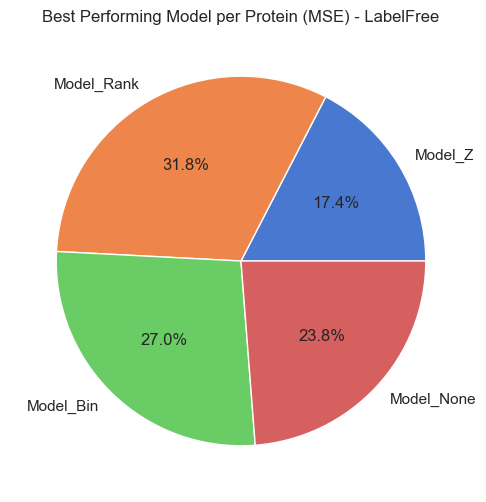


Dataset: TMT


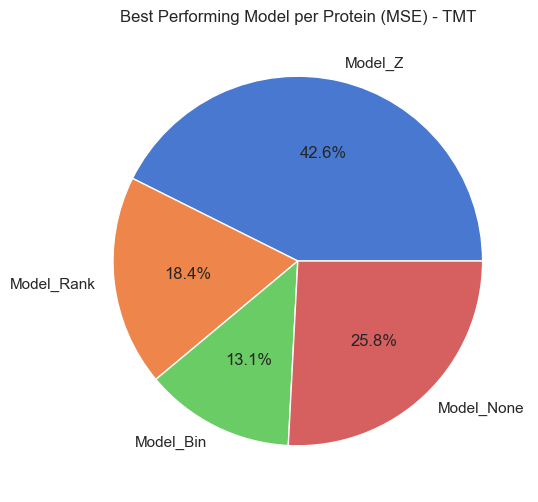

In [14]:
# 3. Winning Model Counts (MSE - Lower is Better)
print("\n=== Winning Model Analysis (MSE) ===")

for ds in datasets_eval:
    print(f"\nDataset: {ds}")
    row = comp_df[comp_df['Dataset'] == ds].iloc[0]
    
    arrays = []
    for m in models:
        arrays.append(row.get(f'{m}_MSE_List', []))
        
    if any(len(x) == 0 for x in arrays): continue
    
    stack = np.vstack(arrays)
    # Find winner (Min MSE)
    winners_idx = np.argmin(stack, axis=0)
    
    counts = Counter(winners_idx)
    
    plt.figure(figsize=(6, 6))
    sizes = [counts.get(i, 0) for i in range(len(models))]
    plt.pie(sizes, labels=[models_indices[i] for i in range(len(models))], autopct='%1.1f%%', colors=palette)
    plt.title(f'Best Performing Model per Protein (MSE) - {ds}')
    plt.show()
